# 胎儿多切面超声图像生成：CycleGAN vs Diffusion

本 Notebook 完整演示整个项目的使用流程：

1. **数据集**（FETAL_PLANES_DB）概览与可视化
2. **数据加载管线**
3. **网络结构**（CycleGAN / Diffusion）与参数量
4. **训练权重加载**
5. **生成结果可视化**
6. **训练损失曲线**
7. **两个模型的性能对比**（FID / SSIM / PSNR）

> 请先按 `README.md` 下载数据集并（可选）训练模型。若尚未训练，本 Notebook
> 仍能展示数据、网络结构，仅生成结果部分会用随机初始化的网络演示。


In [1]:
import os, sys
from pathlib import Path

# 保证在项目根目录运行，并能 import fetalgen 包
ROOT = Path(os.getcwd())
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from fetalgen.config import PLANES, BRAIN_PLANES, CycleGANConfig, DiffusionConfig, resolve_device
from fetalgen.dataset import FetalPlanesDataset, build_dataloader, load_metadata
from fetalgen.models import Generator, Discriminator, UNet, GaussianDiffusion
from fetalgen.metrics import FIDComputer, compute_pairwise_metrics
from fetalgen.utils import count_parameters
from fetalgen import visualize

DEVICE = resolve_device("auto")
print("项目根目录:", ROOT)
print("设备:", DEVICE, "| PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())


项目根目录: e:\jerome\MyCode\FETAL_PLANES_DB_gen
设备: cuda | PyTorch: 2.14.1+cu126 | CUDA: True


## 1. 数据集概览

FETAL_PLANES_DB 包含 12400 张灰度超声图像，分 6 个切面类别。
元数据在 `FETAL_PLANES_DB_data.csv` 中（分号分隔）。

In [2]:
csv_path = "data/FETAL_PLANES_ZENODO/FETAL_PLANES_DB_data.csv"
img_dir  = "data/FETAL_PLANES_ZENODO/Images"

df = load_metadata(csv_path)
print("元数据形状:", df.shape)
print("列名:", list(df.columns))
display(df.head())

print("\n各切面类别数量:")
print(df["Plane"].value_counts().to_string())

print("\n训练/测试划分:")
print(df["Train"].value_counts().rename({1: "train", 0: "test"}).to_string())


元数据形状: (12400, 7)
列名: ['Image_name', 'Patient_num', 'Plane', 'Brain_plane', 'Operator', 'US_Machine', 'Train']


,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train
0,Patient00001_Plane1_1_of_15,1,Other,Not A Brain,Other,Aloka,1
1,Patient00001_Plane1_2_of_15,1,Other,Not A Brain,Other,Aloka,1
2,Patient00001_Plane1_3_of_15,1,Other,Not A Brain,Other,Aloka,1
3,Patient00001_Plane1_4_of_15,1,Other,Not A Brain,Other,Aloka,1
4,Patient00001_Plane1_5_of_15,1,Other,Not A Brain,Other,Aloka,1



各切面类别数量:
Plane
Other              4213
Fetal brain        3092
Fetal thorax       1718
Maternal cervix    1626
Fetal femur        1040
Fetal abdomen       711

训练/测试划分:
Train
train    7129
test     5271


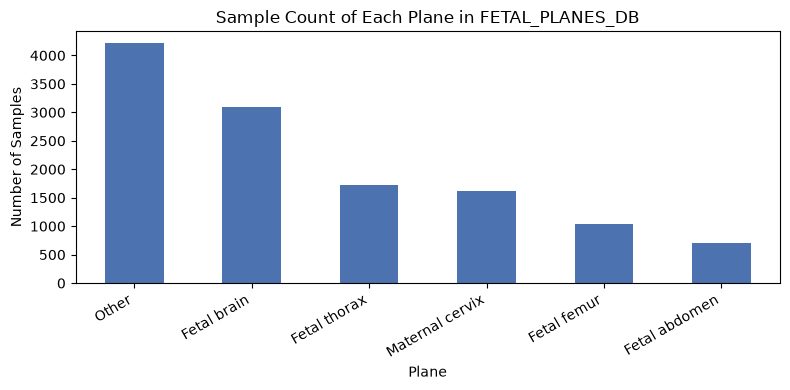

In [3]:
counts = df["Plane"].value_counts()
plt.figure(figsize=(8, 4))
counts.plot(kind="bar", color="#4C72B0")
plt.title("Sample Count of Each Plane in FETAL_PLANES_DB")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 2. 数据可视化

从每个类别采样若干张图像，展示不同切面的形态差异。

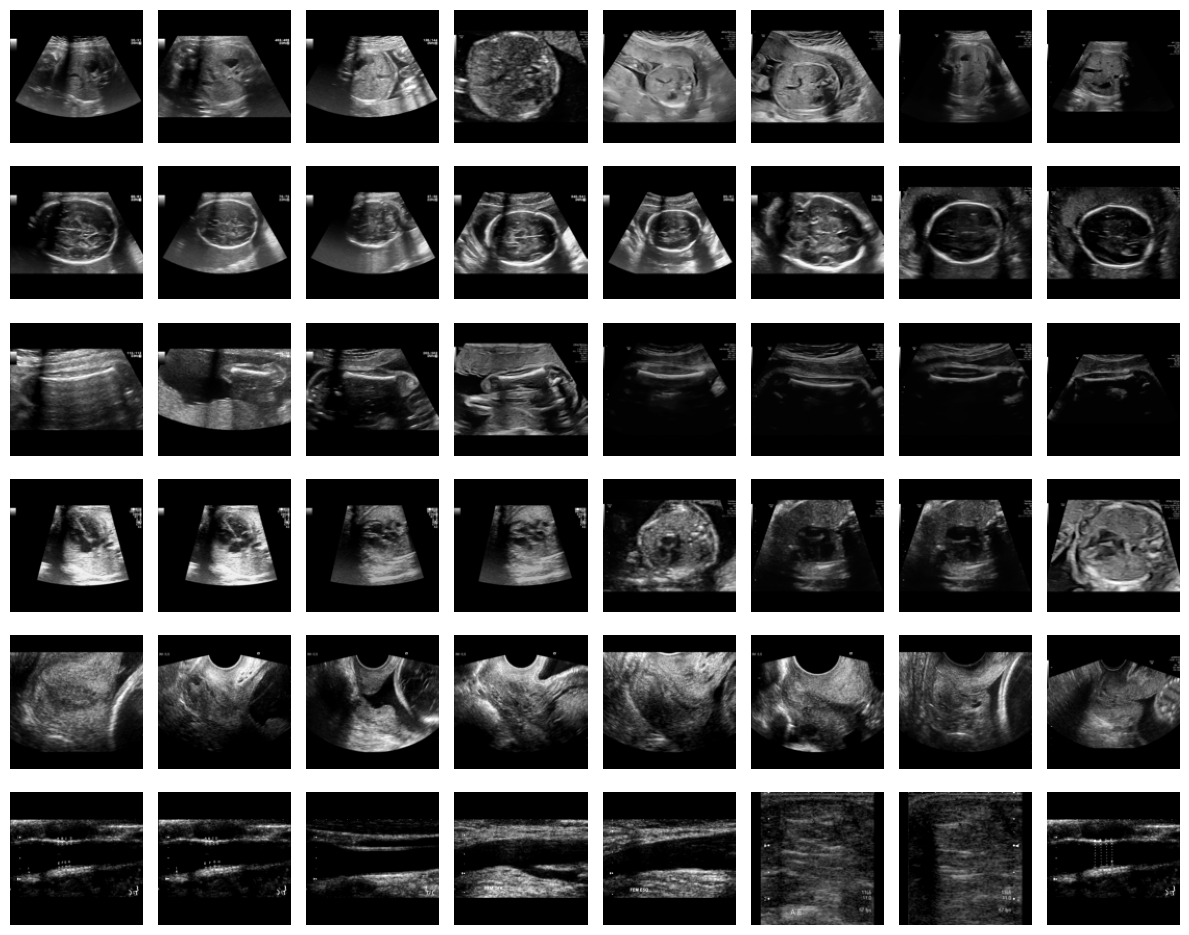

In [4]:
img_size = 128
ds = FetalPlanesDataset(csv_path, img_dir, split="all", img_size=img_size)

images_by_class = {p: [] for p in PLANES}
for i in range(len(ds)):
    img, label = ds[i]
    cls = ds.planes[label]
    if len(images_by_class[cls]) < 8:
        images_by_class[cls].append(img)
    if all(len(v) >= 8 for v in images_by_class.values()):
        break

visualize.show_dataset_samples(images_by_class, n_per_class=8)


## 3. 数据加载管线

展示预处理流程（正方形填充 → 缩放 → 归一化到 [-1,1]）与 DataLoader 输出。

In [5]:
# CycleGAN 翻译的两个域
ds_brain = FetalPlanesDataset(csv_path, img_dir, split="train", planes=["Fetal brain"],
                              img_size=img_size, augment=True)
ds_femur = FetalPlanesDataset(csv_path, img_dir, split="train", planes=["Fetal femur"],
                              img_size=img_size, augment=True)
print("脑部训练样本:", len(ds_brain), "| 股骨训练样本:", len(ds_femur))

# 单个样本
img, label = ds_brain[0]
print("单个样本形状:", tuple(img.shape), "| 取值范围:", float(img.min()), "~", float(img.max()))

# 一个 batch
loader = build_dataloader(csv_path, img_dir, split="train", planes=["Fetal brain"],
                          img_size=img_size, batch_size=8, num_workers=0, augment=True)
batch, labels = next(iter(loader))
print("batch 形状:", tuple(batch.shape), "| 标签:", labels.tolist())


脑部训练样本: 1620 | 股骨训练样本: 516
单个样本形状: (1, 128, 128) | 取值范围: -1.0 ~ 0.4431372880935669
batch 形状: (8, 1, 128, 128) | 标签: [0, 0, 0, 0, 0, 0, 0, 0]


## 4. 网络结构与参数量

In [6]:
# ---- CycleGAN ----
G_AB = Generator(input_nc=1, output_nc=1, ngf=64, n_resblocks=9)
G_BA = Generator(input_nc=1, output_nc=1, ngf=64, n_resblocks=9)
D_A  = Discriminator(input_nc=1, ndf=64, n_layers=3)
D_B  = Discriminator(input_nc=1, ndf=64, n_layers=3)

print("=== CycleGAN ===")
print(f"Generator 参数量:      {count_parameters(G_AB)/1e6:.2f} M")
print(f"Discriminator 参数量:  {count_parameters(D_A)/1e6:.2f} M")

# ---- Diffusion ----
unet = UNet(in_channels=1, out_channels=1, base_channels=64, channel_mults=(1, 2, 4, 8),
            num_res_blocks=2, attention_resolutions=(16, 8), num_classes=6)
diffusion = GaussianDiffusion(unet, timesteps=1000, beta_schedule="cosine")

print("\n=== Diffusion (DDPM) ===")
print(f"U-Net 参数量: {count_parameters(unet)/1e6:.2f} M")
print(f"扩散步数: {diffusion.timesteps} | beta 调度: cosine | 类别条件: 6 类")

# 快速前向验证
x = torch.randn(2, 1, 128, 128)
t = torch.randint(0, 1000, (2,))
c = torch.tensor([0, 3])
print("U-Net 输出形状:", tuple(unet(x, t, c).shape))


=== CycleGAN ===
Generator 参数量:      11.37 M
Discriminator 参数量:  2.76 M

=== Diffusion (DDPM) ===
U-Net 参数量: 51.88 M
扩散步数: 1000 | beta 调度: cosine | 类别条件: 6 类
U-Net 输出形状: (2, 1, 128, 128)


## 5. 加载训练权重

若检查点存在则加载；否则用随机初始化网络演示结构。

In [7]:
from fetalgen.loaders import load_cyclegan, load_diffusion

cyclegan_ckpt = "checkpoints/cyclegan/best_fid.pt"
diffusion_ckpt = "checkpoints/diffusion/latest.pt"

if os.path.exists(cyclegan_ckpt):
    cg_models, _ = load_cyclegan(cyclegan_ckpt, DEVICE)
    G_AB, G_BA = cg_models["G_AB"], cg_models["G_BA"]
    print("已加载 CycleGAN 检查点:", cyclegan_ckpt)
else:
    print("未找到 CycleGAN 检查点，使用随机初始化的网络（仅演示结构）")

if os.path.exists(diffusion_ckpt):
    diffusion, _ = load_diffusion(diffusion_ckpt, DEVICE, use_ema=True)
    print("已加载 Diffusion 检查点:", diffusion_ckpt)
else:
    print("未找到 Diffusion 检查点，使用随机初始化的网络（仅演示结构）")


已加载 CycleGAN 检查点: checkpoints/cyclegan/best_fid.pt
已加载 Diffusion 检查点: checkpoints/diffusion/latest.pt


## 6. CycleGAN 结果可视化

上行输入（Fetal brain），下行翻译结果（Fetal femur）。

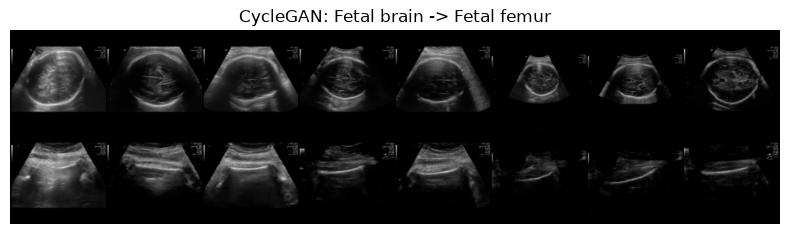

In [8]:
G_AB = G_AB.to(DEVICE).eval()

src = []
loader = build_dataloader(csv_path, img_dir, split="test", planes=["Fetal brain"],
                          img_size=img_size, batch_size=8, num_workers=0, shuffle=False)
for x, _ in loader:
    src.append(x)
    if sum(t.shape[0] for t in src) >= 8:
        break
src = torch.cat(src, dim=0)[:8]

with torch.no_grad():
    fake = G_AB(src.to(DEVICE)).detach().cpu()

visualize.show_grid(torch.cat([src, fake], dim=0), nrow=8,
                    title="CycleGAN: Fetal brain -> Fetal femur")


## 7. Diffusion 结果可视化

每类生成 4 张（6 类共 24 张，每行一类）。

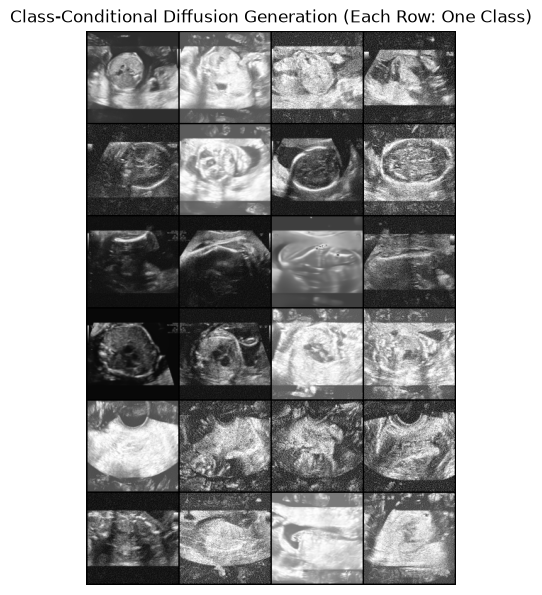

In [9]:
n_classes, per = 6, 4
classes = torch.arange(n_classes).repeat_interleave(per).to(DEVICE)
shape = (classes.shape[0], 1, img_size, img_size)
diffusion = diffusion.to(DEVICE).eval()
with torch.no_grad():
    samples = diffusion.ddim_sample(shape, c=classes, steps=100, eta=0.0,
                                    device=DEVICE).detach().cpu()
visualize.show_grid(samples, nrow=per, title="Class-Conditional Diffusion Generation (Each Row: One Class)")


## 8. 训练曲线

训练过程中每 `log_interval` 步记录一次损失，可从 CSV 直接绘图。

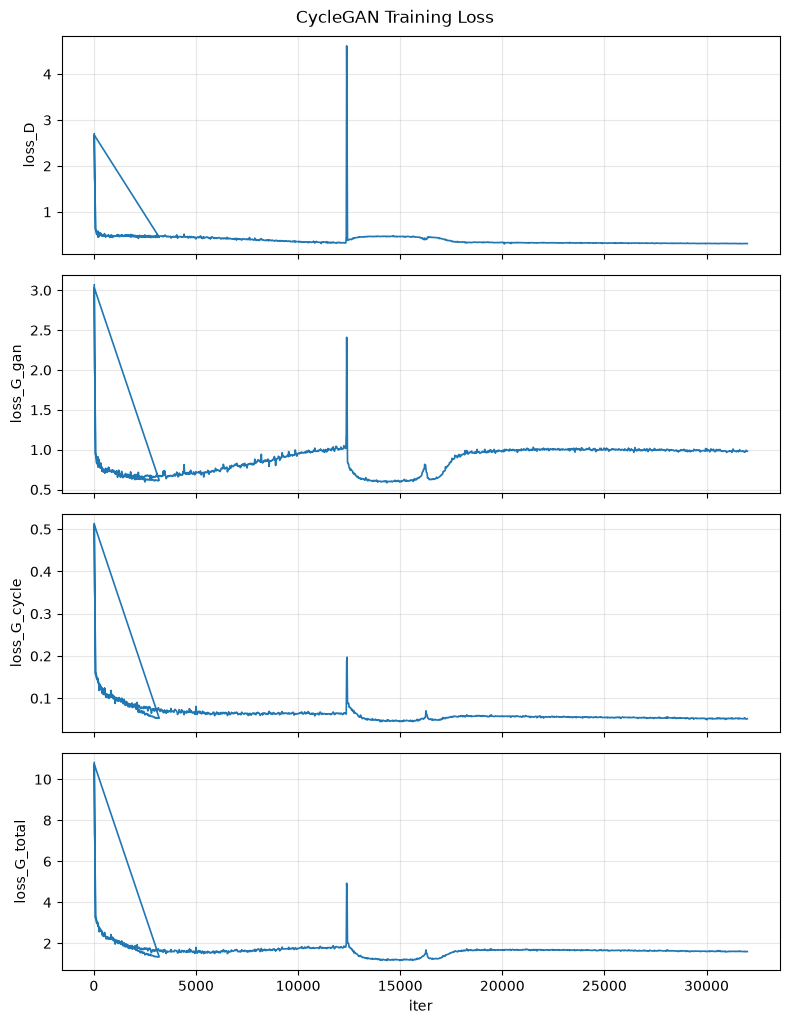

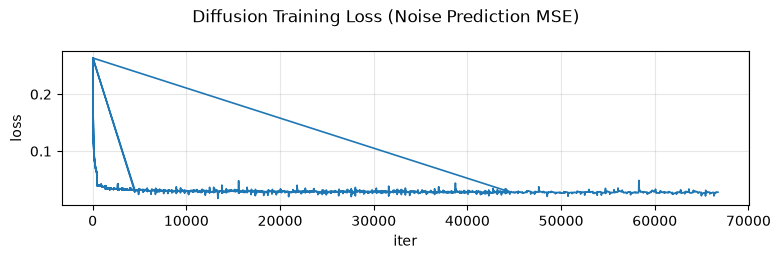

In [10]:
cg_log = "logs/cyclegan/train_log.csv"
diff_log = "logs/diffusion/train_log.csv"
if os.path.exists(cg_log):
    visualize.plot_training_curves(
        cg_log,
        columns=["loss_D", "loss_G_gan", "loss_G_cycle", "loss_G_total"],
        title="CycleGAN Training Loss", x_col="iter")
else:
    print("Not found", cg_log, "(Please train CycleGAN first)")
if os.path.exists(diff_log):
    visualize.plot_training_curves(diff_log, columns=["loss"],
                                   title="Diffusion Training Loss (Noise Prediction MSE)", x_col="iter")
else:
    print("Not found", diff_log, "(Please train Diffusion first)")


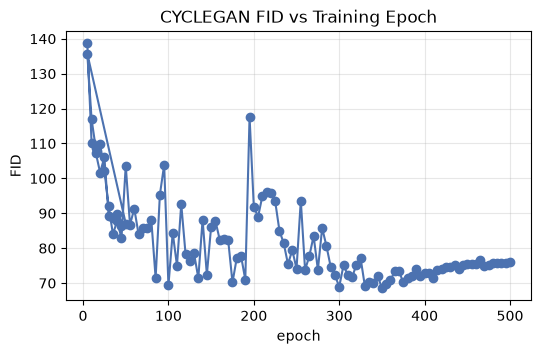

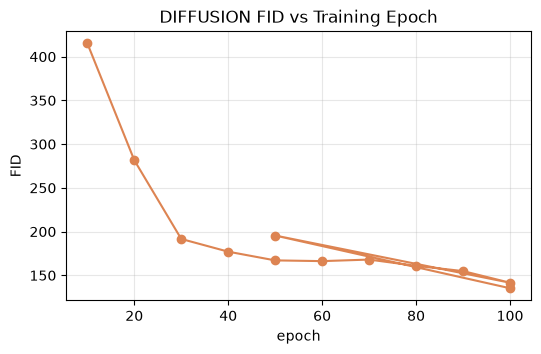

In [11]:
for model in ["cyclegan", "diffusion"]:
    fpath = f"logs/{model}/fid_history.csv"
    if os.path.exists(fpath):
        d = pd.read_csv(fpath)
        plt.figure(figsize=(6, 3.5))
        plt.plot(d["epoch"], d["fid"], marker="o",
                 color="#4C72B0" if model == "cyclegan" else "#DD8452")
        plt.xlabel("epoch"); plt.ylabel("FID")
        plt.title(f"{model.upper()} FID vs Training Epoch")
        plt.grid(alpha=0.3)
        plt.show()
    else:
        print("Not found", fpath)


## 9. 性能对比

汇总两个模型的最佳 FID（及 CycleGAN 的循环一致性 SSIM/PSNR）并绘图对比。

In [12]:
results = {}
for model in ["cyclegan", "diffusion"]:
    fpath = f"logs/{model}/fid_history.csv"
    if os.path.exists(fpath):
        d = pd.read_csv(fpath)
        best = d.loc[d["fid"].idxmin()]
        results[model] = {"FID": float(best["fid"])}
        if model == "cyclegan":
            results[model]["cycle_SSIM"] = float(best["cycle_ssim"])
            results[model]["cycle_PSNR"] = float(best["cycle_psnr"])
        print(f"{model}: 最佳 FID = {best['fid']:.3f} (epoch {int(best['epoch'])})")
    else:
        print(f"{model}: 暂无评估结果（请先训练）")


cyclegan: 最佳 FID = 68.531 (epoch 350)
diffusion: 最佳 FID = 135.232 (epoch 100)


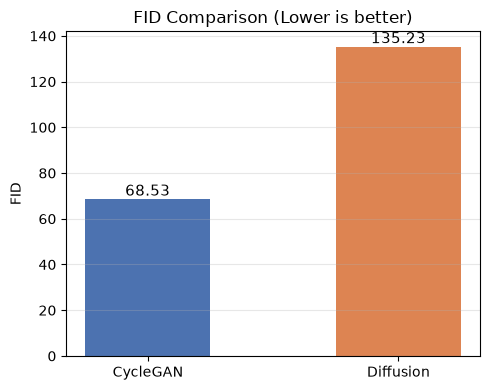

In [13]:
if "cyclegan" in results and "diffusion" in results:
    fid_compare = {"CycleGAN": results["cyclegan"]["FID"],
                   "Diffusion": results["diffusion"]["FID"]}
    visualize.plot_metric_comparison(fid_compare, metric_name="FID", lower_is_better=True)
else:
    print("FID comparison plot will be available after both models are trained.")


## 10. 总结

- **CycleGAN** 擅长**跨切面翻译**：给定一个切面，生成对应目标切面的图像，并通过
  循环一致性保证内容不被破坏（SSIM/PSNR 衡量重建质量）。
- **Diffusion (DDPM)** 擅长**无条件/类别条件生成**：从纯噪声逐步去噪得到逼真图像，
  FID 通常更低、多样性更好，但采样速度较慢（本项目用 DDIM 加速）。

两者都以 **FID** 作为统一的生成质量主指标，可在 `logs/*/fid_history.csv` 中查看
训练过程中的变化趋势。更多细节与复现说明见项目 `README.md`。
